<a href="https://colab.research.google.com/github/Chetalam/cnn-skin-cancer-classification/blob/main/notebooks/06_model_evaluation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 06 — Model Evaluation

Evaluate MobileNetV2, EfficientNet-B0 and ResNet50 on the fixed grouped test set of 408 images. Report accuracy, precision, sensitivity, specificity, F1-score and one-vs-rest ROC-AUC. Keep the deployment choice fixed from validation results. Save confusion matrices, ROC curves, per-image predictions and error reports.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path
from datetime import datetime, timezone
import gc
import hashlib
import json
import shutil
import numpy as np
import pandas as pd
import tensorflow as tf
import sklearn
import matplotlib.pyplot as plt
from sklearn.metrics import (
    accuracy_score, confusion_matrix, precision_recall_fscore_support,
    f1_score, roc_auc_score, roc_curve,
)
from IPython.display import display

print('TensorFlow:', tf.__version__)
print('Keras:', getattr(tf.keras, '__version__', 'bundled'))
print('Scikit-learn:', sklearn.__version__)
print('GPU:', tf.config.list_physical_devices('GPU'))
for gpu in tf.config.list_physical_devices('GPU'):
    tf.config.experimental.set_memory_growth(gpu, True)

PROJECT_ROOT = Path('/content/drive/MyDrive/cnn-skin-cancer-classification')
SPLIT_ROOT = PROJECT_ROOT / 'Datasets' / 'Splits'
RUN_ID = '77751764c605'
MODEL_ROOT = PROJECT_ROOT / 'Models' / 'Transfer_Learning' / RUN_ID
TRAINING_ROOT = PROJECT_ROOT / 'Reports' / 'Training' / RUN_ID
SELECTED_ROOT = PROJECT_ROOT / 'Models' / 'Selected' / RUN_ID
REPORT_ROOT = PROJECT_ROOT / 'Reports' / 'Evaluation' / RUN_ID
LOCAL_ROOT = Path('/content/skin_cancer_test_images')
REPORT_ROOT.mkdir(parents=True, exist_ok=True)
LOCAL_ROOT.mkdir(parents=True, exist_ok=True)
CLASS_NAMES = ['BCC', 'Melanoma', 'SCC']
CLASS_TO_INDEX = {name: index for index, name in enumerate(CLASS_NAMES)}
IMAGE_SIZE = (224, 224)
BATCH_SIZE = 16
PREPROCESSORS = {
    'mobilenet_v2': tf.keras.applications.mobilenet_v2.preprocess_input,
    'efficientnet_b0': tf.keras.applications.efficientnet.preprocess_input,
    'resnet50': tf.keras.applications.resnet50.preprocess_input,
}
MODEL_NAMES = ['MobileNetV2', 'EfficientNetB0', 'ResNet50']

def file_hash(path):
    digest = hashlib.sha256()
    with path.open('rb') as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b''):
            digest.update(block)
    return digest.hexdigest()

def write_json(path, data):
    temporary = path.with_name(path.name + '.tmp')
    temporary.write_text(json.dumps(data, indent=2), encoding='utf-8')
    temporary.replace(path)

Mounted at /content/drive
TensorFlow: 2.21.0
Keras: 3.13.2
Scikit-learn: 1.6.1
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
frames = {}
manifest_hashes = {}
for split in ['train', 'validation', 'test']:
    path = SPLIT_ROOT / f'{split}_metadata.csv'
    if not path.is_file():
        raise FileNotFoundError(path)
    manifest_hashes[split] = file_hash(path)
    frame = pd.read_csv(path, dtype={'patient_id': 'string', 'lesion_id': 'string'})
    if not frame['split'].eq(split).all():
        raise ValueError(f'{split}: invalid split column.')
    if not frame['class_label'].map(CLASS_TO_INDEX).eq(frame['label_index']).all():
        raise ValueError('Class indices differ from training.')
    frames[split] = frame

combined = pd.concat(frames.values(), ignore_index=True)
assert len(combined) == 2703
assert not combined.duplicated(['dataset', 'image_id']).any()
assert combined.groupby('group_id')['split'].nunique().max() == 1
assert combined.groupby('image_hash')['split'].nunique().max() == 1
pad = combined[combined['dataset'] == 'PAD-UFES-20']
assert pad['patient_id'].notna().all()
assert pad.groupby('patient_id')['split'].nunique().max() == 1
lesions = combined.dropna(subset=['lesion_id'])
assert lesions.groupby(['dataset', 'lesion_id'])['split'].nunique().max() == 1

test_frame = frames['test'].copy().reset_index(drop=True)
assert len(test_frame) == 408
assert set(test_frame['class_label']) == set(CLASS_NAMES)
TEST_LABELS = test_frame['label_index'].to_numpy(dtype=np.int32)

metadata = {}
for name in MODEL_NAMES:
    folder = MODEL_ROOT / name
    info = json.loads((folder / 'metadata.json').read_text())
    if not info.get('training_complete') or info['run_id'] != RUN_ID:
        raise ValueError(f'{name}: training is incomplete or run ID differs.')
    if info['class_names'] != CLASS_NAMES or info['image_size'] != list(IMAGE_SIZE):
        raise ValueError(f'{name}: input shape or class order differs.')
    if info['manifest_hashes'] != manifest_hashes:
        raise ValueError(f'{name}: manifests changed after training.')
    if file_hash(folder / 'best.keras') != info['model_sha256']:
        raise ValueError(f'{name}: saved model checksum differs.')
    if info['preprocessing'] not in PREPROCESSORS:
        raise ValueError(f'{name}: unknown preprocessing.')
    metadata[name] = info

selected_metadata = json.loads((SELECTED_ROOT / 'metadata.json').read_text())
SELECTED_NAME = selected_metadata['model_name']
assert SELECTED_NAME == 'EfficientNetB0'
assert selected_metadata['run_id'] == RUN_ID
assert file_hash(SELECTED_ROOT / 'model.keras') == metadata[SELECTED_NAME]['model_sha256']
print('Verified training run:', RUN_ID)
print('Fixed validation-selected model:', SELECTED_NAME)
print('Test records:', len(test_frame))
display(test_frame.groupby(['dataset', 'class_label']).size().rename('image_count').reset_index())

Verified training run: 77751764c605
Fixed validation-selected model: EfficientNetB0
Test records: 408


,dataset,class_label,image_count
0,HAM10000,BCC,72
1,HAM10000,Melanoma,173
2,PAD-UFES-20,BCC,125
3,PAD-UFES-20,Melanoma,9
4,PAD-UFES-20,SCC,29


In [ ]:
local_paths = []
for position, row in enumerate(test_frame.itertuples(index=False)):
    source = Path(row.image_path)
    if not source.is_file():
        raise FileNotFoundError(source)
    key = hashlib.sha256(str(source).encode()).hexdigest()
    destination = LOCAL_ROOT / (key + source.suffix.lower())
    if not destination.is_file() or destination.stat().st_size != source.stat().st_size:
        temporary = destination.with_suffix(destination.suffix + '.tmp')
        shutil.copyfile(source, temporary)
        temporary.replace(destination)
    local_paths.append(str(destination))
    if (position + 1) % 100 == 0:
        print('Test images copied:', position + 1)
test_frame['local_path'] = local_paths

def read_image(path):
    image = tf.io.decode_image(tf.io.read_file(path), channels=3, expand_animations=False)
    image.set_shape([None, None, 3])
    return tf.image.resize(tf.cast(image, tf.float32), IMAGE_SIZE, method='bilinear')

RAW_TEST = tf.data.Dataset.from_tensor_slices(np.asarray(local_paths, dtype=str))
RAW_TEST = RAW_TEST.map(read_image, num_parallel_calls=tf.data.AUTOTUNE).cache().batch(BATCH_SIZE)
for _ in RAW_TEST:
    pass
print('Test image pipeline ready. No augmentation or shuffling applied.')

Test images copied: 100
Test images copied: 200
Test images copied: 300
Test images copied: 400
Test image pipeline ready. No augmentation or shuffling applied.


In [ ]:
def compute_metrics(labels, probabilities):
    predicted = probabilities.argmax(axis=1)
    matrix = confusion_matrix(labels, predicted, labels=np.arange(3))
    tp = np.diag(matrix).astype(float)
    fn = matrix.sum(axis=1) - tp
    fp = matrix.sum(axis=0) - tp
    tn = matrix.sum() - tp - fn - fp
    specificity = np.divide(tn, tn + fp, out=np.full(3, np.nan), where=(tn + fp) != 0)
    precision, recall, f1, support = precision_recall_fscore_support(
        labels, predicted, labels=np.arange(3), zero_division=0,
    )
    auc_values = [
        float(roc_auc_score((labels == index).astype(int), probabilities[:, index]))
        if np.unique(labels == index).size == 2 else np.nan
        for index in range(3)
    ]
    per_class = pd.DataFrame({
        'class_label': CLASS_NAMES, 'support': support,
        'precision': precision, 'sensitivity_recall': recall,
        'specificity_ovr': specificity, 'f1_score': f1,
        'roc_auc_ovr': auc_values,
        'true_positive': tp.astype(int), 'false_negative': fn.astype(int),
        'false_positive': fp.astype(int), 'true_negative': tn.astype(int),
    })
    summary = {
        'accuracy': float(accuracy_score(labels, predicted)),
        'macro_precision': float(precision.mean()),
        'macro_sensitivity': float(recall.mean()),
        'macro_specificity': float(np.nanmean(specificity)),
        'macro_f1': float(f1.mean()),
        'macro_roc_auc_ovr': float(roc_auc_score(
            labels, probabilities, labels=np.arange(3), multi_class='ovr', average='macro',
        )),
        'test_records': len(labels),
    }
    return summary, per_class, matrix

def save_figures(name, labels, probabilities, matrix, folder):
    fig, ax = plt.subplots(figsize=(6, 5))
    display_image = ax.imshow(matrix, cmap='Blues')
    fig.colorbar(display_image, ax=ax)
    ax.set(xticks=np.arange(3), yticks=np.arange(3), xticklabels=CLASS_NAMES,
           yticklabels=CLASS_NAMES, xlabel='Predicted class', ylabel='Actual class',
           title=name + ' — test confusion matrix')
    for row in range(3):
        for column in range(3):
            ax.text(column, row, str(matrix[row, column]), ha='center', va='center',
                    color='white' if matrix[row, column] > matrix.max() / 2 else 'black')
    fig.tight_layout()
    fig.savefig(folder / 'confusion_matrix.png', dpi=180)
    plt.show()
    plt.close(fig)
    fig, ax = plt.subplots(figsize=(6, 5))
    for index, class_name in enumerate(CLASS_NAMES):
        binary = (labels == index).astype(int)
        fpr, tpr, _ = roc_curve(binary, probabilities[:, index])
        auc = roc_auc_score(binary, probabilities[:, index])
        ax.plot(fpr, tpr, label=f'{class_name}: AUC={auc:.3f}')
    ax.plot([0, 1], [0, 1], '--', color='grey')
    ax.set(xlabel='False positive rate', ylabel='True positive rate', title=name + ' — one-vs-rest ROC')
    ax.legend()
    fig.tight_layout()
    fig.savefig(folder / 'roc_curves.png', dpi=180)
    plt.show()
    plt.close(fig)


EVALUATING: MobileNetV2
26/26 ━━━━━━━━━━━━━━━━━━━━ 7s 260ms/step
Saved-model validation reference: passed


,class_label,support,precision,sensitivity_recall,specificity_ovr,f1_score,roc_auc_ovr,true_positive,false_negative,false_positive,true_negative
0,BCC,197,0.8242,0.7614,0.8483,0.7916,0.8800,150,47,32,179
1,Melanoma,182,0.8814,0.8571,0.9071,0.8691,0.9579,156,26,21,205
2,SCC,29,0.3061,0.5172,0.9103,0.3846,0.8450,15,14,34,345


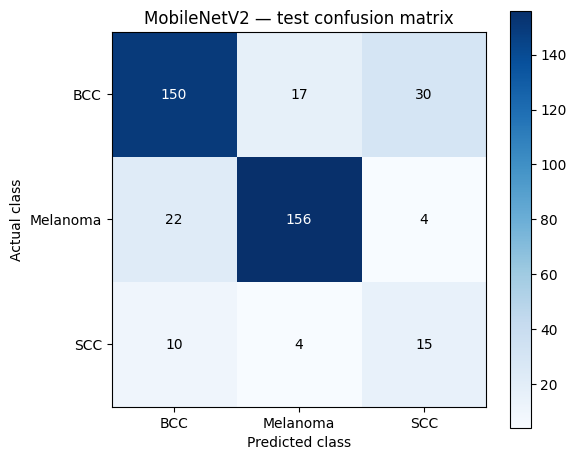

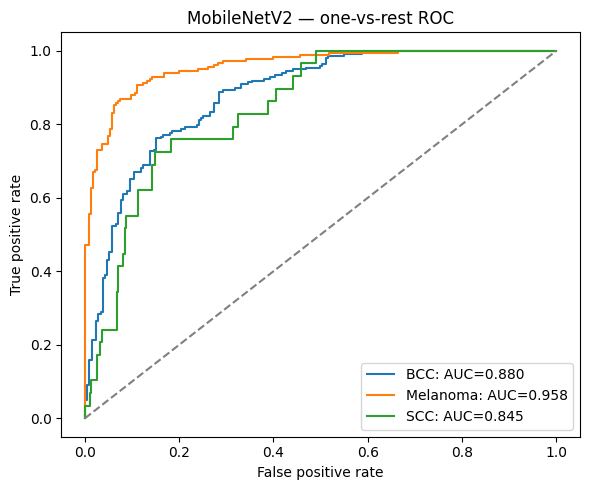


EVALUATING: EfficientNetB0
26/26 ━━━━━━━━━━━━━━━━━━━━ 10s 400ms/step
Saved-model validation reference: passed


,class_label,support,precision,sensitivity_recall,specificity_ovr,f1_score,roc_auc_ovr,true_positive,false_negative,false_positive,true_negative
0,BCC,197,0.8306,0.7716,0.8531,0.8000,0.9036,152,45,31,180
1,Melanoma,182,0.8777,0.9066,0.8982,0.8919,0.9696,165,17,23,203
2,SCC,29,0.3784,0.4828,0.9393,0.4242,0.8874,14,15,23,356


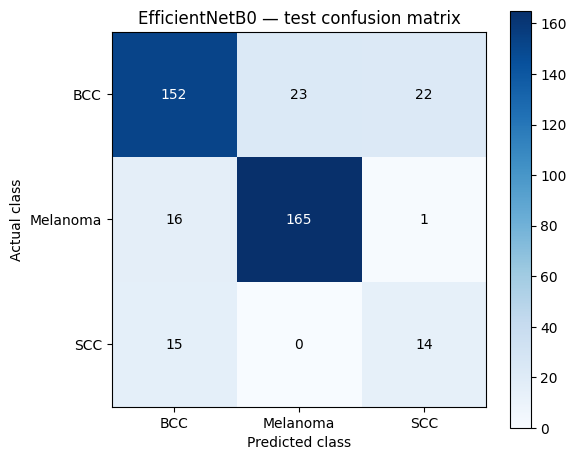

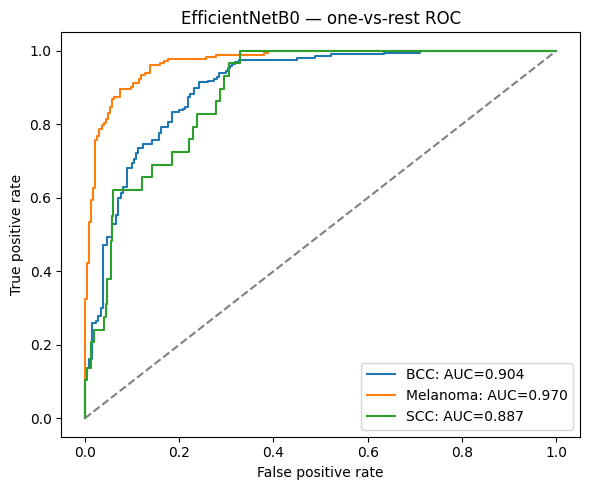


EVALUATING: ResNet50
26/26 ━━━━━━━━━━━━━━━━━━━━ 6s 235ms/step
Saved-model validation reference: passed


,class_label,support,precision,sensitivity_recall,specificity_ovr,f1_score,roc_auc_ovr,true_positive,false_negative,false_positive,true_negative
0,BCC,197,0.8358,0.8528,0.8436,0.8442,0.9258,168,29,33,178
1,Melanoma,182,0.9185,0.9286,0.9336,0.9235,0.9846,169,13,15,211
2,SCC,29,0.3913,0.3103,0.9631,0.3462,0.8848,9,20,14,365


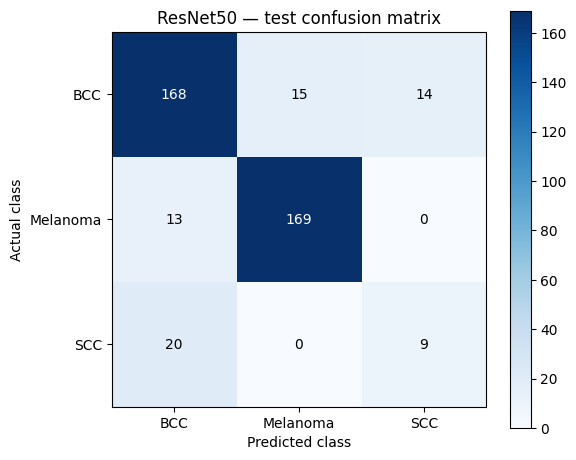

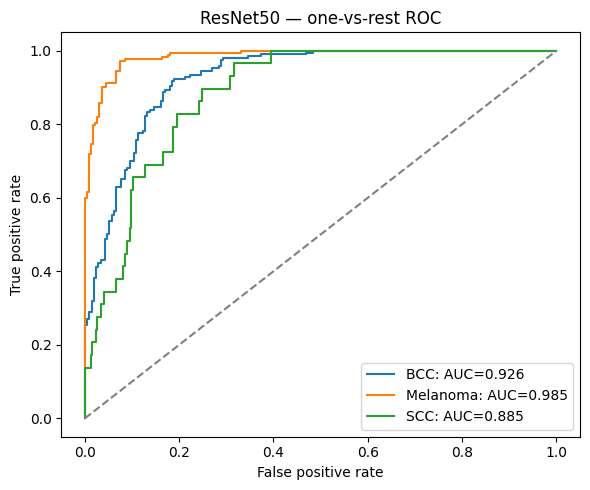

In [ ]:
summaries = []
all_predictions = {}
for name in MODEL_NAMES:
    tf.keras.backend.clear_session()
    gc.collect()
    info = metadata[name]
    folder = REPORT_ROOT / name
    folder.mkdir(parents=True, exist_ok=True)
    preprocess = PREPROCESSORS[info['preprocessing']]
    model = tf.keras.models.load_model(MODEL_ROOT / name / 'best.keras', compile=False)

    # Verify saved-model outputs against notebook 5's validation reference.
    reference_frame = pd.read_csv(TRAINING_ROOT / name / 'validation_reference_images.csv')
    with np.load(TRAINING_ROOT / name / 'validation_reference.npz') as archive:
        reference_scores = archive['scores'].copy()
        reference_labels = archive['labels'].copy()
    assert np.array_equal(reference_labels, reference_frame['label_index'].to_numpy())
    reference_images = tf.stack([read_image(str(path)) for path in reference_frame['image_path']])
    current_scores = model.predict(preprocess(reference_images), verbose=0)
    np.testing.assert_allclose(current_scores, reference_scores, rtol=1e-3, atol=1e-4)

    test_ds = RAW_TEST.map(preprocess, num_parallel_calls=tf.data.AUTOTUNE).prefetch(tf.data.AUTOTUNE)
    print('\nEVALUATING:', name)
    probabilities = model.predict(test_ds, verbose=1)
    if probabilities.shape != (len(test_frame), 3) or not np.isfinite(probabilities).all():
        raise ValueError('Invalid model output shape or scores.')
    if (probabilities < 0).any():
        raise ValueError('Negative softmax scores found.')
    np.testing.assert_allclose(probabilities.sum(axis=1), 1.0, atol=1e-5)
    summary, per_class, matrix = compute_metrics(TEST_LABELS, probabilities)
    summary.update({'model_name': name, 'selected_from_validation': name == SELECTED_NAME,
                    'validation_macro_f1': info['validation_macro_f1']})
    summaries.append(summary)
    all_predictions[name] = probabilities
    per_class.to_csv(folder / 'per_class_metrics.csv', index=False)
    write_json(folder / 'test_metrics.json', summary)
    pd.DataFrame(matrix, index=CLASS_NAMES, columns=CLASS_NAMES).to_csv(folder / 'confusion_matrix.csv')
    predictions = test_frame.drop(columns=['local_path']).copy()
    predicted = probabilities.argmax(axis=1)
    predictions['predicted_class'] = np.asarray(CLASS_NAMES)[predicted]
    predictions['model_score'] = probabilities.max(axis=1)
    predictions['correct'] = predicted == TEST_LABELS
    for index, class_name in enumerate(CLASS_NAMES):
        predictions[f'score_{class_name}'] = probabilities[:, index]
    predictions.to_csv(folder / 'test_predictions.csv', index=False)
    predictions[~predictions['correct']].to_csv(folder / 'misclassified_images.csv', index=False)

    source_rows = []
    for dataset_name, indices in test_frame.groupby('dataset').groups.items():
        indices = np.asarray(list(indices))
        source_labels = TEST_LABELS[indices]
        source_predictions = predicted[indices]
        present_classes = np.unique(source_labels)
        source_rows.append({
            'dataset': dataset_name, 'image_count': len(indices),
            'represented_classes': ', '.join(CLASS_NAMES[index] for index in present_classes),
            'accuracy': float(accuracy_score(source_labels, source_predictions)),
            'macro_f1_present_classes': float(f1_score(source_labels, source_predictions,
                labels=present_classes, average='macro', zero_division=0)),
        })
    pd.DataFrame(source_rows).to_csv(folder / 'metrics_by_dataset.csv', index=False)
    print('Saved-model validation reference: passed')
    display(per_class.round(4))
    save_figures(name, TEST_LABELS, probabilities, matrix, folder)
    del model, test_ds, reference_images
    gc.collect()

In [ ]:
comparison = pd.DataFrame(summaries)
columns = ['model_name', 'selected_from_validation', 'accuracy', 'macro_sensitivity',
           'macro_specificity', 'macro_f1', 'macro_roc_auc_ovr']
comparison.to_csv(REPORT_ROOT / 'test_model_comparison.csv', index=False)
display(comparison[columns].round(4))
selected_result = next(row for row in summaries if row['model_name'] == SELECTED_NAME)
write_json(SELECTED_ROOT / 'test_metrics.json', selected_result)
shutil.copyfile(REPORT_ROOT / SELECTED_NAME / 'per_class_metrics.csv', SELECTED_ROOT / 'per_class_metrics.csv')
write_json(REPORT_ROOT / 'evaluation_manifest.json', {
    'run_id': RUN_ID, 'selected_model': SELECTED_NAME,
    'selection_basis': 'validation macro F1; unchanged after test evaluation',
    'manifest_hashes': manifest_hashes, 'class_names': CLASS_NAMES,
    'tensorflow_version': tf.__version__, 'sklearn_version': sklearn.__version__,
    'evaluated_at_utc': datetime.now(timezone.utc).isoformat(),
    'test_records': len(test_frame),
})
print('MODEL EVALUATION COMPLETE')
print('Deployment candidate remains:', SELECTED_NAME)
print('Selected-model test accuracy:', round(selected_result['accuracy'], 4))
print('Selected-model test macro F1:', round(selected_result['macro_f1'], 4))
print('Proposal accuracy target (>= 0.85):', selected_result['accuracy'] >= 0.85)
print('Proposal macro F1 target (> 0.80):', selected_result['macro_f1'] > 0.80)
print('Reports saved to:', REPORT_ROOT)
print('Selected model package:', SELECTED_ROOT)

,model_name,selected_from_validation,accuracy,macro_sensitivity,macro_specificity,macro_f1,macro_roc_auc_ovr
0,MobileNetV2,False,0.7868,0.7119,0.8886,0.6818,0.8943
1,EfficientNetB0,True,0.8113,0.7203,0.8969,0.7054,0.9202
2,ResNet50,False,0.8480,0.6972,0.9134,0.7046,0.9317


MODEL EVALUATION COMPLETE
Deployment candidate remains: EfficientNetB0
Selected-model test accuracy: 0.8113
Selected-model test macro F1: 0.7054
Proposal accuracy target (>= 0.85): False
Proposal macro F1 target (> 0.80): False
Reports saved to: /content/drive/MyDrive/cnn-skin-cancer-classification/Reports/Evaluation/77751764c605
Selected model package: /content/drive/MyDrive/cnn-skin-cancer-classification/Models/Selected/77751764c605


## Interpretation and limitations

The deployment model was selected using validation macro F1 before test evaluation. Test results are reported for all models, but do not change that selection.

The classifier has no benign/no-cancer class. Model scores are not calibrated clinical probabilities. SCC support is small and SCC occurs only in PAD-UFES-20, creating potential dataset-source confounding. HAM patient-level separation cannot be established because patient identifiers are unavailable. Performance on these datasets does not establish clinical validity or performance on Kenyan patients or darker skin tones.

Record the actual test results and whether the proposal targets were met. Do not claim targets were met if the measured results are lower.

## Experiment 2 — Follow-up Evaluation

Evaluate the Experiment 2 MobileNetV2, EfficientNetB0 and ResNet50 checkpoints on the existing grouped test set. ResNet50 was selected before this evaluation using validation macro F1 (0.692982).

Report accuracy, per-class precision, recall/sensitivity, specificity, F1 and ROC-AUC; compare both experiments and examine SCC. Check selected-model test accuracy ≥0.85 and test macro F1 >0.80 without changing selection based on test scores.

The test set has already been inspected. These results are follow-up evaluation, not an independent fresh final assessment.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path
from datetime import datetime, timezone
import gc
import hashlib
import json
import shutil
import numpy as np
import pandas as pd
import tensorflow as tf
import sklearn
import matplotlib.pyplot as plt
from sklearn.metrics import (
    accuracy_score, confusion_matrix, precision_recall_fscore_support,
    f1_score, roc_auc_score, roc_curve,
)
from IPython.display import display

print('TensorFlow:', tf.__version__)
print('Keras:', getattr(tf.keras, '__version__', 'bundled'))
print('Scikit-learn:', sklearn.__version__)
print('GPU:', tf.config.list_physical_devices('GPU'))
for gpu in tf.config.list_physical_devices('GPU'):
    try:
        tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError:
        print('GPU already initialized; retaining its existing memory configuration.')

PROJECT_ROOT = Path('/content/drive/MyDrive/cnn-skin-cancer-classification')
SPLIT_ROOT = PROJECT_ROOT / 'Datasets' / 'Splits'
RUN_ID = 'exp02_65b8c20800f3'
BASELINE_RUN_ID = '77751764c605'
MODEL_ROOT = PROJECT_ROOT / 'Models' / 'Transfer_Learning' / RUN_ID
TRAINING_ROOT = PROJECT_ROOT / 'Reports' / 'Training' / RUN_ID
SELECTED_ROOT = PROJECT_ROOT / 'Models' / 'Selected' / RUN_ID
REPORT_ROOT = PROJECT_ROOT / 'Reports' / 'Evaluation' / RUN_ID
LOCAL_ROOT = Path('/content/skin_cancer_test_images')
REPORT_ROOT.mkdir(parents=True, exist_ok=True)
LOCAL_ROOT.mkdir(parents=True, exist_ok=True)
CLASS_NAMES = ['BCC', 'Melanoma', 'SCC']
CLASS_TO_INDEX = {name: index for index, name in enumerate(CLASS_NAMES)}
IMAGE_SIZE = (224, 224)
BATCH_SIZE = 16
PREPROCESSORS = {
    'mobilenet_v2': tf.keras.applications.mobilenet_v2.preprocess_input,
    'efficientnet_b0': tf.keras.applications.efficientnet.preprocess_input,
    'resnet50': tf.keras.applications.resnet50.preprocess_input,
}
MODEL_NAMES = ['MobileNetV2', 'EfficientNetB0', 'ResNet50']

def file_hash(path):
    digest = hashlib.sha256()
    with path.open('rb') as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b''):
            digest.update(block)
    return digest.hexdigest()

def write_json(path, data):
    temporary = path.with_name(path.name + '.tmp')
    temporary.write_text(json.dumps(data, indent=2), encoding='utf-8')
    temporary.replace(path)

Mounted at /content/drive
TensorFlow: 2.21.0
Keras: 3.13.2
Scikit-learn: 1.6.1
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [3]:
# Recover the selected Experiment 2 package without retraining.
source_folder = MODEL_ROOT / "ResNet50"
source_model = source_folder / "best.keras"
source_metadata = source_folder / "metadata.json"

if not source_model.is_file() or not source_metadata.is_file():
    raise FileNotFoundError(
        f"ResNet50 checkpoint or metadata is missing from {source_folder}"
    )

info = json.loads(source_metadata.read_text())

if (
    info.get("model_name") != "ResNet50"
    or info.get("run_id") != RUN_ID
    or not info.get("training_complete")
):
    raise ValueError("ResNet50 metadata does not match completed Experiment 2.")

if file_hash(source_model) != info["model_sha256"]:
    raise ValueError("ResNet50 model checksum failed. Stop here.")

# Confirm ResNet50 was the validation winner across both experiments.
candidates = []
for run in [BASELINE_RUN_ID, RUN_ID]:
    for name in MODEL_NAMES:
        path = (
            PROJECT_ROOT / "Models" / "Transfer_Learning"
            / run / name / "metadata.json"
        )
        candidate = json.loads(path.read_text())
        if not candidate.get("training_complete"):
            raise ValueError(f"Incomplete training: {run}/{name}")
        candidates.append(candidate)

winner = sorted(
    candidates,
    key=lambda row: (
        -row["validation_macro_f1"],
        0 if row["run_id"] == BASELINE_RUN_ID else 1,
        row["model_name"],
    ),
)[0]

if winner["run_id"] != RUN_ID or winner["model_name"] != "ResNet50":
    raise ValueError(
        "Saved validation results do not select Experiment 2 ResNet50."
    )

SELECTED_ROOT.mkdir(parents=True, exist_ok=True)
destination = SELECTED_ROOT / "model.keras"

if destination.exists():
    if file_hash(destination) != info["model_sha256"]:
        raise ValueError(
            "A different model already exists in the selected folder. "
            "Stop and inspect it."
        )
else:
    temporary = SELECTED_ROOT / "model.keras.tmp"
    shutil.copy2(source_model, temporary)
    if file_hash(temporary) != info["model_sha256"]:
        raise ValueError("Copied model checksum failed.")
    temporary.replace(destination)

recovered_metadata = {
    **info,
    "model_file": str(destination),
    "comparison_run_id": RUN_ID,
    "selected_experiment": "Experiment 2",
    "original_test_results_already_inspected": True,
    "checkpoint_selection_uses_validation_only": True,
}

metadata_path = SELECTED_ROOT / "metadata.json"
if not metadata_path.exists():
    write_json(metadata_path, recovered_metadata)

classes_path = SELECTED_ROOT / "class_names.json"
if not classes_path.exists():
    write_json(classes_path, CLASS_NAMES)

print("Selected package ready:", SELECTED_ROOT)
print("Model:", info["model_name"])
print("Validation macro F1:", info["validation_macro_f1"])
print("No retraining was performed.")

Selected package ready: /content/drive/MyDrive/cnn-skin-cancer-classification/Models/Selected/exp02_65b8c20800f3
Model: ResNet50
Validation macro F1: 0.6929823978337054
No retraining was performed.


In [4]:
frames = {}
manifest_hashes = {}
for split in ['train', 'validation', 'test']:
    path = SPLIT_ROOT / f'{split}_metadata.csv'
    if not path.is_file():
        raise FileNotFoundError(path)
    manifest_hashes[split] = file_hash(path)
    frame = pd.read_csv(path, dtype={'patient_id': 'string', 'lesion_id': 'string'})
    if not frame['split'].eq(split).all():
        raise ValueError(f'{split}: invalid split column.')
    if not frame['class_label'].map(CLASS_TO_INDEX).eq(frame['label_index']).all():
        raise ValueError('Class indices differ from training.')
    frames[split] = frame

combined = pd.concat(frames.values(), ignore_index=True)
assert len(combined) == 2703
assert not combined.duplicated(['dataset', 'image_id']).any()
assert combined.groupby('group_id')['split'].nunique().max() == 1
assert combined.groupby('image_hash')['split'].nunique().max() == 1
pad = combined[combined['dataset'] == 'PAD-UFES-20']
assert pad['patient_id'].notna().all()
assert pad.groupby('patient_id')['split'].nunique().max() == 1
lesions = combined.dropna(subset=['lesion_id'])
assert lesions.groupby(['dataset', 'lesion_id'])['split'].nunique().max() == 1

test_frame = frames['test'].copy().reset_index(drop=True)
assert len(test_frame) == 408
assert set(test_frame['class_label']) == set(CLASS_NAMES)
TEST_LABELS = test_frame['label_index'].to_numpy(dtype=np.int32)

metadata = {}
for name in MODEL_NAMES:
    folder = MODEL_ROOT / name
    info = json.loads((folder / 'metadata.json').read_text())
    if not info.get('training_complete') or info['run_id'] != RUN_ID:
        raise ValueError(f'{name}: training is incomplete or run ID differs.')
    if info['class_names'] != CLASS_NAMES or info['image_size'] != list(IMAGE_SIZE):
        raise ValueError(f'{name}: input shape or class order differs.')
    if info['manifest_hashes'] != manifest_hashes:
        raise ValueError(f'{name}: manifests changed after training.')
    if file_hash(folder / 'best.keras') != info['model_sha256']:
        raise ValueError(f'{name}: saved model checksum differs.')
    if info['preprocessing'] not in PREPROCESSORS:
        raise ValueError(f'{name}: unknown preprocessing.')
    metadata[name] = info

selected_metadata = json.loads((SELECTED_ROOT / 'metadata.json').read_text())
SELECTED_NAME = selected_metadata['model_name']
assert SELECTED_NAME == 'ResNet50'
assert selected_metadata['run_id'] == RUN_ID
assert selected_metadata['comparison_run_id'] == RUN_ID
assert selected_metadata['manifest_hashes'] == manifest_hashes
assert selected_metadata['class_names'] == CLASS_NAMES
assert file_hash(SELECTED_ROOT / 'model.keras') == metadata[SELECTED_NAME]['model_sha256']
print('Verified training run:', RUN_ID)
print('Fixed validation-selected model:', SELECTED_NAME)
print('Test records:', len(test_frame))
display(test_frame.groupby(['dataset', 'class_label']).size().rename('image_count').reset_index())

Verified training run: exp02_65b8c20800f3
Fixed validation-selected model: ResNet50
Test records: 408


,dataset,class_label,image_count
0,HAM10000,BCC,72
1,HAM10000,Melanoma,173
2,PAD-UFES-20,BCC,125
3,PAD-UFES-20,Melanoma,9
4,PAD-UFES-20,SCC,29


In [5]:
local_paths = []
for position, row in enumerate(test_frame.itertuples(index=False)):
    source = Path(row.image_path)
    if not source.is_file():
        raise FileNotFoundError(source)
    key = hashlib.sha256(str(source).encode()).hexdigest()
    destination = LOCAL_ROOT / (key + source.suffix.lower())
    if not destination.is_file() or destination.stat().st_size != source.stat().st_size:
        temporary = destination.with_suffix(destination.suffix + '.tmp')
        shutil.copyfile(source, temporary)
        temporary.replace(destination)
    local_paths.append(str(destination))
    if (position + 1) % 100 == 0:
        print('Test images copied:', position + 1)
test_frame['local_path'] = local_paths

def read_image(path):
    image = tf.io.decode_image(tf.io.read_file(path), channels=3, expand_animations=False)
    image.set_shape([None, None, 3])
    return tf.image.resize(tf.cast(image, tf.float32), IMAGE_SIZE, method='bilinear')

RAW_TEST = tf.data.Dataset.from_tensor_slices(np.asarray(local_paths, dtype=str))
RAW_TEST = RAW_TEST.map(read_image, num_parallel_calls=tf.data.AUTOTUNE).cache().batch(BATCH_SIZE)
for _ in RAW_TEST:
    pass
print('Test image pipeline ready. No augmentation or shuffling applied.')

Test images copied: 100
Test images copied: 200
Test images copied: 300
Test images copied: 400
Test image pipeline ready. No augmentation or shuffling applied.


In [6]:
def compute_metrics(labels, probabilities):
    predicted = probabilities.argmax(axis=1)
    matrix = confusion_matrix(labels, predicted, labels=np.arange(3))
    tp = np.diag(matrix).astype(float)
    fn = matrix.sum(axis=1) - tp
    fp = matrix.sum(axis=0) - tp
    tn = matrix.sum() - tp - fn - fp
    specificity = np.divide(tn, tn + fp, out=np.full(3, np.nan), where=(tn + fp) != 0)
    precision, recall, f1, support = precision_recall_fscore_support(
        labels, predicted, labels=np.arange(3), zero_division=0,
    )
    auc_values = [
        float(roc_auc_score((labels == index).astype(int), probabilities[:, index]))
        if np.unique(labels == index).size == 2 else np.nan
        for index in range(3)
    ]
    per_class = pd.DataFrame({
        'class_label': CLASS_NAMES, 'support': support,
        'precision': precision, 'sensitivity_recall': recall,
        'specificity_ovr': specificity, 'f1_score': f1,
        'roc_auc_ovr': auc_values,
        'true_positive': tp.astype(int), 'false_negative': fn.astype(int),
        'false_positive': fp.astype(int), 'true_negative': tn.astype(int),
    })
    summary = {
        'accuracy': float(accuracy_score(labels, predicted)),
        'macro_precision': float(precision.mean()),
        'macro_sensitivity': float(recall.mean()),
        'macro_specificity': float(np.nanmean(specificity)),
        'macro_f1': float(f1.mean()),
        'macro_roc_auc_ovr': float(roc_auc_score(
            labels, probabilities, labels=np.arange(3), multi_class='ovr', average='macro',
        )),
        'test_records': len(labels),
    }
    return summary, per_class, matrix

def save_figures(name, labels, probabilities, matrix, folder):
    fig, ax = plt.subplots(figsize=(6, 5))
    display_image = ax.imshow(matrix, cmap='Blues')
    fig.colorbar(display_image, ax=ax)
    ax.set(xticks=np.arange(3), yticks=np.arange(3), xticklabels=CLASS_NAMES,
           yticklabels=CLASS_NAMES, xlabel='Predicted class', ylabel='Actual class',
           title=name + ' — test confusion matrix')
    for row in range(3):
        for column in range(3):
            ax.text(column, row, str(matrix[row, column]), ha='center', va='center',
                    color='white' if matrix[row, column] > matrix.max() / 2 else 'black')
    fig.tight_layout()
    fig.savefig(folder / 'confusion_matrix.png', dpi=180)
    plt.show()
    plt.close(fig)
    fig, ax = plt.subplots(figsize=(6, 5))
    for index, class_name in enumerate(CLASS_NAMES):
        binary = (labels == index).astype(int)
        fpr, tpr, _ = roc_curve(binary, probabilities[:, index])
        auc = roc_auc_score(binary, probabilities[:, index])
        ax.plot(fpr, tpr, label=f'{class_name}: AUC={auc:.3f}')
    ax.plot([0, 1], [0, 1], '--', color='grey')
    ax.set(xlabel='False positive rate', ylabel='True positive rate', title=name + ' — one-vs-rest ROC')
    ax.legend()
    fig.tight_layout()
    fig.savefig(folder / 'roc_curves.png', dpi=180)
    plt.show()
    plt.close(fig)


EVALUATING: MobileNetV2
26/26 ━━━━━━━━━━━━━━━━━━━━ 11s 450ms/step
Saved-model validation reference: passed


,class_label,support,precision,sensitivity_recall,specificity_ovr,f1_score,roc_auc_ovr,true_positive,false_negative,false_positive,true_negative
0,BCC,197,0.8562,0.6954,0.8910,0.7675,0.9124,137,60,23,188
1,Melanoma,182,0.8535,0.9286,0.8717,0.8895,0.9647,169,13,29,197
2,SCC,29,0.2800,0.4828,0.9050,0.3544,0.8630,14,15,36,343


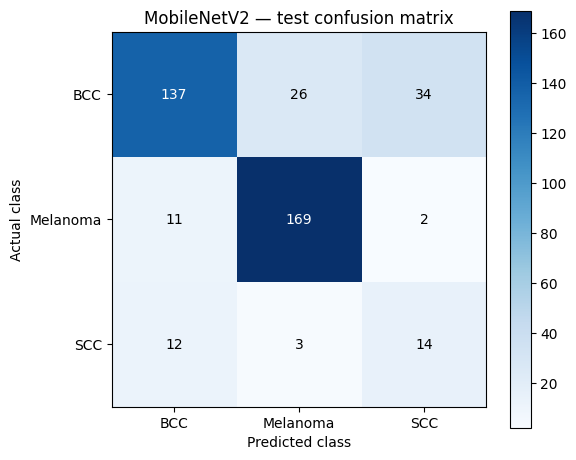

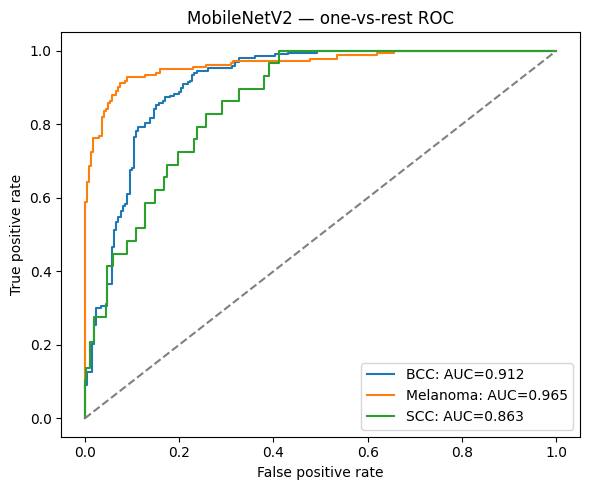


EVALUATING: EfficientNetB0
26/26 ━━━━━━━━━━━━━━━━━━━━ 10s 402ms/step
Saved-model validation reference: passed


,class_label,support,precision,sensitivity_recall,specificity_ovr,f1_score,roc_auc_ovr,true_positive,false_negative,false_positive,true_negative
0,BCC,197,0.8848,0.8579,0.8957,0.8711,0.9360,169,28,22,189
1,Melanoma,182,0.9115,0.9615,0.9248,0.9358,0.9843,175,7,17,209
2,SCC,29,0.5200,0.4483,0.9683,0.4815,0.8995,13,16,12,367


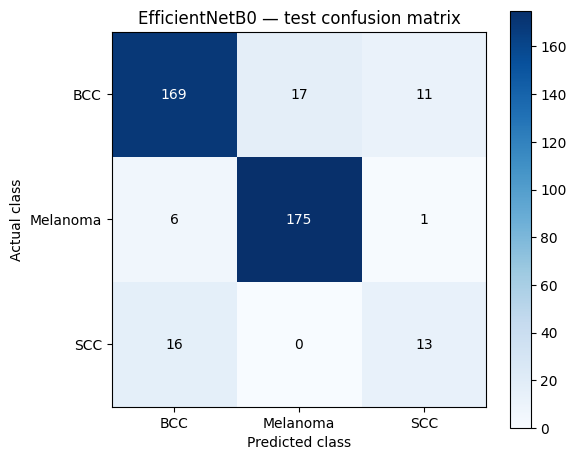

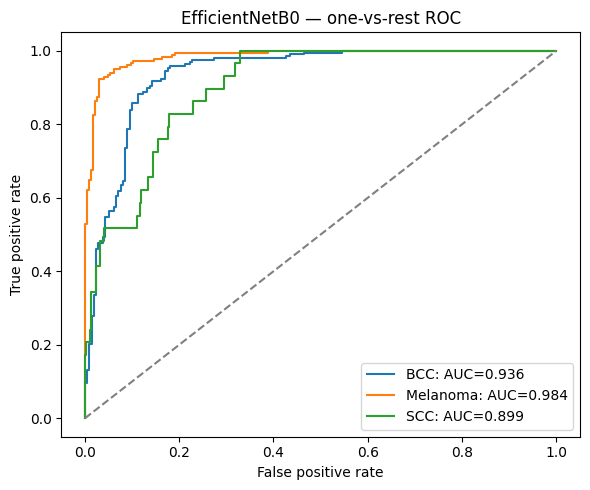


EVALUATING: ResNet50
26/26 ━━━━━━━━━━━━━━━━━━━━ 6s 233ms/step
Saved-model validation reference: passed


,class_label,support,precision,sensitivity_recall,specificity_ovr,f1_score,roc_auc_ovr,true_positive,false_negative,false_positive,true_negative
0,BCC,197,0.8564,0.8477,0.8673,0.8520,0.9447,167,30,28,183
1,Melanoma,182,0.9441,0.9286,0.9558,0.9363,0.9919,169,13,10,216
2,SCC,29,0.4118,0.4828,0.9472,0.4444,0.9106,14,15,20,359


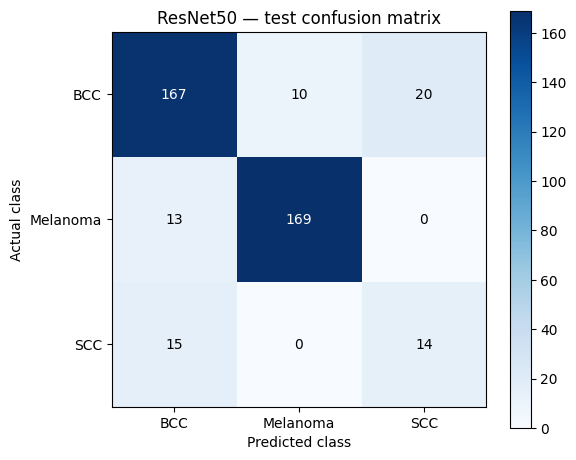

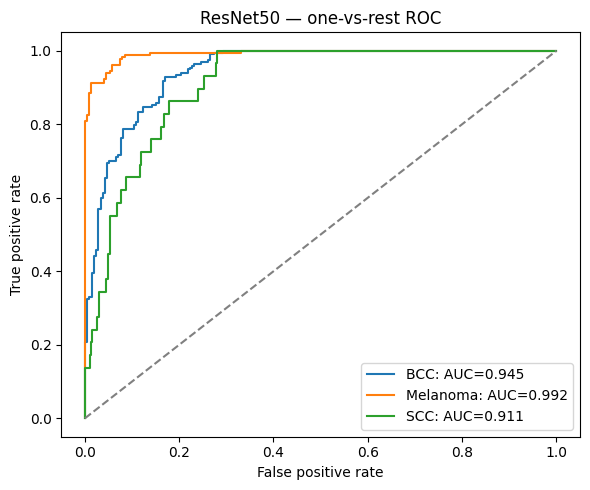

In [7]:
summaries = []
all_predictions = {}
for name in MODEL_NAMES:
    tf.keras.backend.clear_session()
    gc.collect()
    info = metadata[name]
    folder = REPORT_ROOT / name
    folder.mkdir(parents=True, exist_ok=True)
    preprocess = PREPROCESSORS[info['preprocessing']]
    model = tf.keras.models.load_model(MODEL_ROOT / name / 'best.keras', compile=False)

    # Verify saved-model outputs against notebook 5's validation reference.
    reference_frame = pd.read_csv(TRAINING_ROOT / name / 'validation_reference_images.csv')
    with np.load(TRAINING_ROOT / name / 'validation_reference.npz') as archive:
        reference_scores = archive['scores'].copy()
        reference_labels = archive['labels'].copy()
    assert np.array_equal(reference_labels, reference_frame['label_index'].to_numpy())
    reference_images = tf.stack([read_image(str(path)) for path in reference_frame['image_path']])
    current_scores = model.predict(preprocess(reference_images), verbose=0)
    np.testing.assert_allclose(current_scores, reference_scores, rtol=1e-3, atol=1e-4)

    test_ds = RAW_TEST.map(preprocess, num_parallel_calls=tf.data.AUTOTUNE).prefetch(tf.data.AUTOTUNE)
    print('\nEVALUATING:', name)
    probabilities = model.predict(test_ds, verbose=1)
    if probabilities.shape != (len(test_frame), 3) or not np.isfinite(probabilities).all():
        raise ValueError('Invalid model output shape or scores.')
    if (probabilities < 0).any():
        raise ValueError('Negative softmax scores found.')
    np.testing.assert_allclose(probabilities.sum(axis=1), 1.0, atol=1e-5)
    summary, per_class, matrix = compute_metrics(TEST_LABELS, probabilities)
    summary.update({'model_name': name, 'selected_from_validation': name == SELECTED_NAME,
                    'validation_macro_f1': info['validation_macro_f1'],
                    'run_id': RUN_ID, 'experiment': 'Experiment 2',
                    'evaluation_type': 'follow-up on previously inspected test set'})
    summaries.append(summary)
    all_predictions[name] = probabilities
    per_class.to_csv(folder / 'per_class_metrics.csv', index=False)
    write_json(folder / 'test_metrics.json', summary)
    pd.DataFrame(matrix, index=CLASS_NAMES, columns=CLASS_NAMES).to_csv(folder / 'confusion_matrix.csv')
    predictions = test_frame.drop(columns=['local_path']).copy()
    predicted = probabilities.argmax(axis=1)
    predictions['predicted_class'] = np.asarray(CLASS_NAMES)[predicted]
    predictions['model_score'] = probabilities.max(axis=1)
    predictions['correct'] = predicted == TEST_LABELS
    for index, class_name in enumerate(CLASS_NAMES):
        predictions[f'score_{class_name}'] = probabilities[:, index]
    predictions.to_csv(folder / 'test_predictions.csv', index=False)
    predictions[~predictions['correct']].to_csv(folder / 'misclassified_images.csv', index=False)

    source_rows = []
    for dataset_name, indices in test_frame.groupby('dataset').groups.items():
        indices = np.asarray(list(indices))
        source_labels = TEST_LABELS[indices]
        source_predictions = predicted[indices]
        present_classes = np.unique(source_labels)
        source_rows.append({
            'dataset': dataset_name, 'image_count': len(indices),
            'represented_classes': ', '.join(CLASS_NAMES[index] for index in present_classes),
            'accuracy': float(accuracy_score(source_labels, source_predictions)),
            'macro_f1_present_classes': float(f1_score(source_labels, source_predictions,
                labels=present_classes, average='macro', zero_division=0)),
        })
    pd.DataFrame(source_rows).to_csv(folder / 'metrics_by_dataset.csv', index=False)
    print('Saved-model validation reference: passed')
    display(per_class.round(4))
    save_figures(name, TEST_LABELS, probabilities, matrix, folder)
    del model, test_ds, reference_images
    gc.collect()

In [8]:
comparison = pd.DataFrame(summaries)
columns = ['model_name', 'selected_from_validation', 'accuracy', 'macro_sensitivity',
           'macro_specificity', 'macro_f1', 'macro_roc_auc_ovr']
comparison.to_csv(REPORT_ROOT / 'test_model_comparison.csv', index=False)
display(comparison[columns].round(4))
selected_result = next(row for row in summaries if row['model_name'] == SELECTED_NAME)
write_json(SELECTED_ROOT / 'test_metrics.json', selected_result)
shutil.copyfile(REPORT_ROOT / SELECTED_NAME / 'per_class_metrics.csv', SELECTED_ROOT / 'per_class_metrics.csv')
write_json(REPORT_ROOT / 'evaluation_manifest.json', {
    'run_id': RUN_ID, 'selected_model': SELECTED_NAME,
    'selection_basis': 'validation macro F1; unchanged after test evaluation',
    'manifest_hashes': manifest_hashes, 'class_names': CLASS_NAMES,
    'tensorflow_version': tf.__version__, 'sklearn_version': sklearn.__version__,
    'evaluated_at_utc': datetime.now(timezone.utc).isoformat(),
    'test_records': len(test_frame),
    'evaluation_type': 'follow-up evaluation',
    'original_test_results_already_inspected': True,
    'test_images_used_for_gradient_updates': False,
    'candidate_selected_before_this_evaluation': True,
})
print('MODEL EVALUATION COMPLETE')
print('Deployment candidate remains:', SELECTED_NAME)
print('Selected-model test accuracy:', round(selected_result['accuracy'], 4))
print('Selected-model test macro F1:', round(selected_result['macro_f1'], 4))
print('Proposal accuracy target (>= 0.85):', selected_result['accuracy'] >= 0.85)
print('Proposal macro F1 target (> 0.80):', selected_result['macro_f1'] > 0.80)
print('Reports saved to:', REPORT_ROOT)
print('Selected model package:', SELECTED_ROOT)

,model_name,selected_from_validation,accuracy,macro_sensitivity,macro_specificity,macro_f1,macro_roc_auc_ovr
0,MobileNetV2,False,0.7843,0.7023,0.8892,0.6705,0.9134
1,EfficientNetB0,False,0.8750,0.7559,0.9296,0.7628,0.9399
2,ResNet50,True,0.8578,0.7530,0.9234,0.7443,0.9491


MODEL EVALUATION COMPLETE
Deployment candidate remains: ResNet50
Selected-model test accuracy: 0.8578
Selected-model test macro F1: 0.7443
Proposal accuracy target (>= 0.85): True
Proposal macro F1 target (> 0.80): False
Reports saved to: /content/drive/MyDrive/cnn-skin-cancer-classification/Reports/Evaluation/exp02_65b8c20800f3
Selected model package: /content/drive/MyDrive/cnn-skin-cancer-classification/Models/Selected/exp02_65b8c20800f3


In [9]:
baseline_root = PROJECT_ROOT / 'Reports' / 'Evaluation' / BASELINE_RUN_ID
baseline_manifest = json.loads((baseline_root / 'evaluation_manifest.json').read_text())
if baseline_manifest['manifest_hashes'] != manifest_hashes:
    raise ValueError('Experiment 1 evaluation used different manifests.')
baseline = pd.read_csv(baseline_root / 'test_model_comparison.csv')
baseline['experiment'] = 'Experiment 1'
baseline['run_id'] = BASELINE_RUN_ID
current = comparison.copy()
current['experiment'] = 'Experiment 2'
combined_results = pd.concat([baseline, current], ignore_index=True)
columns = ['experiment', 'model_name', 'selected_from_validation',
           'accuracy', 'macro_f1', 'macro_sensitivity',
           'macro_specificity', 'macro_roc_auc_ovr']
combined_results.to_csv(REPORT_ROOT / 'experiments_test_comparison.csv', index=False)
display(combined_results[columns].round(4))

changes = []
scc_rows = []
for name in MODEL_NAMES:
    old = baseline.loc[baseline['model_name'] == name].iloc[0]
    new = current.loc[current['model_name'] == name].iloc[0]
    changes.append({
        'model_name': name,
        'accuracy_change': new['accuracy'] - old['accuracy'],
        'macro_f1_change': new['macro_f1'] - old['macro_f1'],
    })
    for experiment, folder in [('Experiment 1', baseline_root),
                               ('Experiment 2', REPORT_ROOT)]:
        metrics = pd.read_csv(folder / name / 'per_class_metrics.csv')
        row = metrics.loc[metrics['class_label'] == 'SCC'].iloc[0]
        scc_rows.append({
            'experiment': experiment, 'model_name': name,
            **{key: row[key] for key in ['support', 'precision',
                'sensitivity_recall', 'f1_score', 'false_negative']},
        })
changes = pd.DataFrame(changes)
scc_comparison = pd.DataFrame(scc_rows)
changes.to_csv(REPORT_ROOT / 'test_metric_changes.csv', index=False)
scc_comparison.to_csv(REPORT_ROOT / 'scc_experiments_comparison.csv', index=False)
print('Changes are fractions; multiply by 100 for percentage-point changes.')
display(changes.round(4))
print('SCC comparison:')
display(scc_comparison.round(4))

accuracy_pass = selected_result['accuracy'] >= 0.85
f1_pass = selected_result['macro_f1'] > 0.80
requirements = pd.DataFrame([
    {'requirement': 'Selected model test accuracy >= 0.85',
     'observed': selected_result['accuracy'], 'met': accuracy_pass},
    {'requirement': 'Selected model test macro F1 > 0.80',
     'observed': selected_result['macro_f1'], 'met': f1_pass},
])
requirements.to_csv(REPORT_ROOT / 'requirements_check.csv', index=False)
display(requirements)

# Generate a factual Markdown results cell from the computed scores.
def markdown_table(frame):
    header = '| ' + ' | '.join(map(str, frame.columns)) + ' |'
    separator = '| ' + ' | '.join(['---'] * len(frame.columns)) + ' |'
    rows = ['| ' + ' | '.join(map(str, values)) + ' |'
            for values in frame.itertuples(index=False, name=None)]
    return '\n'.join([header, separator, *rows])

report_text = (
    '## Experiment 2 — Follow-up Test Evaluation\n\n'
    f'The validation-selected candidate remained **{SELECTED_NAME}** '
    f'(run `{RUN_ID}`); the test scores did not change this selection.\n\n'
    + markdown_table(combined_results[columns].round(4)) + '\n\n'
    + '### SCC performance\n\n'
    + markdown_table(scc_comparison.round(4)) + '\n\n'
    + '### Required targets\n\n'
    + f'- Selected-model test accuracy: **{selected_result["accuracy"]:.2%}**; '
    + f'target ≥85%: **{"Met" if accuracy_pass else "Not met"}**.\n'
    + f'- Selected-model test macro F1: **{selected_result["macro_f1"]:.4f}**; '
    + f'target >0.80: **{"Met" if f1_pass else "Not met"}**.\n\n'
    + 'The test set was previously inspected after Experiment 1. These are '
    + 'follow-up results, not an independent fresh final assessment. '
    + 'SCC has only 29 test images and occurs only in PAD-UFES-20; '
    + 'dataset-source confounding and limited sample size remain limitations. '
    + 'There is no benign/no-cancer class, and scores are not calibrated '
    + 'clinical probabilities. Clinical validity has not been established.\n'
)
(REPORT_ROOT / 'experiment_2_results.md').write_text(report_text, encoding='utf-8')
print('Copy the following into your final Text cell:')
print(report_text)

,experiment,model_name,selected_from_validation,accuracy,macro_f1,macro_sensitivity,macro_specificity,macro_roc_auc_ovr
0,Experiment 1,MobileNetV2,False,0.7868,0.6818,0.7119,0.8886,0.8943
1,Experiment 1,EfficientNetB0,True,0.8113,0.7054,0.7203,0.8969,0.9202
2,Experiment 1,ResNet50,False,0.8480,0.7046,0.6972,0.9134,0.9317
3,Experiment 2,MobileNetV2,False,0.7843,0.6705,0.7023,0.8892,0.9134
4,Experiment 2,EfficientNetB0,False,0.8750,0.7628,0.7559,0.9296,0.9399
5,Experiment 2,ResNet50,True,0.8578,0.7443,0.7530,0.9234,0.9491


Changes are fractions; multiply by 100 for percentage-point changes.


,model_name,accuracy_change,macro_f1_change
0,MobileNetV2,-0.0025,-0.0113
1,EfficientNetB0,0.0637,0.0574
2,ResNet50,0.0098,0.0396


SCC comparison:


,experiment,model_name,support,precision,sensitivity_recall,f1_score,false_negative
0,Experiment 1,MobileNetV2,29,0.3061,0.5172,0.3846,14
1,Experiment 2,MobileNetV2,29,0.2800,0.4828,0.3544,15
2,Experiment 1,EfficientNetB0,29,0.3784,0.4828,0.4242,15
3,Experiment 2,EfficientNetB0,29,0.5200,0.4483,0.4815,16
4,Experiment 1,ResNet50,29,0.3913,0.3103,0.3462,20
5,Experiment 2,ResNet50,29,0.4118,0.4828,0.4444,15


,requirement,observed,met
0,Selected model test accuracy >= 0.85,0.857843,True
1,Selected model test macro F1 > 0.80,0.744258,False


Copy the following into your final Text cell:
## Experiment 2 — Follow-up Test Evaluation

The validation-selected candidate remained **ResNet50** (run `exp02_65b8c20800f3`); the test scores did not change this selection.

| experiment | model_name | selected_from_validation | accuracy | macro_f1 | macro_sensitivity | macro_specificity | macro_roc_auc_ovr |
| --- | --- | --- | --- | --- | --- | --- | --- |
| Experiment 1 | MobileNetV2 | False | 0.7868 | 0.6818 | 0.7119 | 0.8886 | 0.8943 |
| Experiment 1 | EfficientNetB0 | True | 0.8113 | 0.7054 | 0.7203 | 0.8969 | 0.9202 |
| Experiment 1 | ResNet50 | False | 0.848 | 0.7046 | 0.6972 | 0.9134 | 0.9317 |
| Experiment 2 | MobileNetV2 | False | 0.7843 | 0.6705 | 0.7023 | 0.8892 | 0.9134 |
| Experiment 2 | EfficientNetB0 | False | 0.875 | 0.7628 | 0.7559 | 0.9296 | 0.9399 |
| Experiment 2 | ResNet50 | True | 0.8578 | 0.7443 | 0.753 | 0.9234 | 0.9491 |

### SCC performance

| experiment | model_name | support | precision | sensitivity_recall 

## Experiment 2 — Follow-up Test Evaluation

ResNet50 remained the candidate selected using validation macro F1.
Test results did not change that selection.

### Comparison of test results

| Experiment | Model | Test accuracy | Test macro F1 |
|---|---|---:|---:|
| Experiment 1 | MobileNetV2 | 78.68% | 0.6818 |
| Experiment 1 | EfficientNetB0 | 81.13% | 0.7054 |
| Experiment 1 | ResNet50 | 84.80% | 0.7046 |
| Experiment 2 | MobileNetV2 | 78.43% | 0.6705 |
| Experiment 2 | EfficientNetB0 | 87.50% | 0.7628 |
| Experiment 2 | ResNet50 | 85.78% | 0.7443 |

EfficientNetB0 and ResNet50 improved in test accuracy and macro F1.
MobileNetV2 declined slightly.

Experiment 2 EfficientNetB0 achieved higher test accuracy and macro F1
than ResNet50. However, ResNet50 remained the selected candidate
because it had the highest validation macro F1. Choosing a different
model from these test results would use the test set for model selection.

### SCC performance

Each model was evaluated on 29 SCC images.

| Experiment | Model | SCC precision | SCC recall | SCC F1 | SCC false negatives |
|---|---|---:|---:|---:|---:|
| Experiment 1 | MobileNetV2 | 0.3061 | 0.5172 | 0.3846 | 14 |
| Experiment 2 | MobileNetV2 | 0.2800 | 0.4828 | 0.3544 | 15 |
| Experiment 1 | EfficientNetB0 | 0.3784 | 0.4828 | 0.4242 | 15 |
| Experiment 2 | EfficientNetB0 | 0.5200 | 0.4483 | 0.4815 | 16 |
| Experiment 1 | ResNet50 | 0.3913 | 0.3103 | 0.3462 | 20 |
| Experiment 2 | ResNet50 | 0.4118 | 0.4828 | 0.4444 | 15 |

ResNet50 improved SCC precision, recall and F1, reducing missed SCC
images from 20 to 15. SCC performance nevertheless remains weak.

EfficientNetB0 improved SCC precision and F1, but its SCC recall
declined and missed SCC images increased from 15 to 16.
Therefore, its SCC improvement was not consistent across all metrics.

### Required targets for the selected ResNet50 model

| Requirement | Observed result | Status |
|---|---:|---|
| Test accuracy ≥85% | 85.78% | Met |
| Test macro F1 >0.80 | 0.7443 | Not met |

Experiment 2 met the accuracy target on this follow-up evaluation,
but did not meet the macro F1 target. Further improvement is needed,
particularly for SCC.

### Limitations

The test set was previously inspected after Experiment 1.
These results are follow-up evaluation, not a fresh independent
final assessment.

SCC has only 29 test images and occurs only in PAD-UFES-20,
creating limited sample precision and potential dataset-source
confounding. There is no benign/no-cancer class. Model scores are
not calibrated clinical probabilities, and clinical validity has
not been established.

Selected run: exp02_65b8c20800f3